# 04 Classification and decision trees: Poor days and AQI groups

**Syllabus units:** Logistic and multinomial regression (5 marks), Decision trees (5 marks).
**Outputs:** `outputs/tables/classifier_comparison.csv`, `models/classifier_models.json` (used by the app).

Targets (built in notebook 01):
* **Poor_Flag** = 1 when AQI > 200 (Poor, Very Poor or Severe), else 0;
* **AQI_Group** = Low (AQI ≤ 100), Moderate (101-200), High (> 200).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold, cross_val_score
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from src.utils import *
set_plot_style()

df = load_clean()
print("cleaned dataset:", df.shape)
print(df["Poor_Flag"].value_counts(normalize=True).round(3).rename({0: "not Poor", 1: "Poor"}))

cleaned dataset: (1826, 19)
Poor_Flag
Poor        0.68
not Poor    0.32
Name: proportion, dtype: float64


## Part A: Logistic regression for a Poor day
The logistic function turns a linear score η = β0 + β1x1 + ... into a probability p = 1 / (1 + e^(-η)), so each
coefficient is a change in the **log-odds** of a Poor day. Predictors: nine pollutants plus season (Winter = baseline).

In [2]:
season_d = pd.get_dummies(df["Season"]).drop(columns="Winter").astype(float)
season_d = season_d[["Summer", "Monsoon", "Post-monsoon"]]
X = pd.concat([df[POLLUTANTS], season_d], axis=1)
y = df["Poor_Flag"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

logit = sm.Logit(y_tr, sm.add_constant(X_tr)).fit(disp=0)
print(logit.summary())
lr_stat = 2 * (logit.llf - logit.llnull)
print(f"\nLikelihood-ratio test vs intercept-only: chi2 = {lr_stat:.1f}, df = {int(logit.df_model)}, p = {logit.llr_pvalue:.3g}")
print(f"McFadden pseudo R-squared = {logit.prsquared:.3f}")

                           Logit Regression Results                           
Dep. Variable:              Poor_Flag   No. Observations:                 1460
Model:                          Logit   Df Residuals:                     1447
Method:                           MLE   Df Model:                           12
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.7410
Time:                        10:38:52   Log-Likelihood:                -237.16
converged:                       True   LL-Null:                       -915.83
Covariance Type:            nonrobust   LLR p-value:                2.177e-283
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const          -11.1393      1.058    -10.529      0.000     -13.213      -9.066
PM2.5            0.0525      0.008      6.466      0.000       0.037       0.068
PM10             0.0246      0.003      8.53

### Wald tests and odds ratios
The Wald statistic for each coefficient is (β / SE)², compared with a chi-square with 1 df (equivalently, the z
column above). Odds ratio = e^β: the multiplicative change in the odds of a Poor day for a one-unit increase.

In [3]:
wald = pd.DataFrame({"coef": logit.params, "SE": logit.bse, "Wald chi2": (logit.params / logit.bse) ** 2,
                     "p-value": logit.pvalues, "Odds ratio": np.exp(logit.params),
                     "OR 2.5%": np.exp(logit.conf_int()[0]), "OR 97.5%": np.exp(logit.conf_int()[1])}).drop("const")
wald["significant"] = wald["p-value"] < ALPHA
save_table(wald.round(4).reset_index(names="Variable"), "logit_wald_odds")
wald.round(3)

,coef,SE,Wald chi2,p-value,Odds ratio,OR 2.5%,OR 97.5%,significant
PM2.5,0.053,0.008,41.812,0.000,1.054,1.037,1.071,True
PM10,0.025,0.003,72.780,0.000,1.025,1.019,1.031,True
NO,-0.020,0.011,3.228,0.072,0.980,0.959,1.002,False
NO2,-0.029,0.014,4.210,0.040,0.971,0.944,0.999,True
NOx,0.030,0.005,38.690,0.000,1.031,1.021,1.041,True
NH3,0.027,0.015,3.252,0.071,1.027,0.998,1.058,False
CO,0.596,0.090,44.193,0.000,1.814,1.522,2.163,True
SO2,0.019,0.026,0.551,0.458,1.019,0.969,1.073,False
O3,0.037,0.009,18.809,0.000,1.038,1.021,1.056,True
Summer,-0.620,0.500,1.537,0.215,0.538,0.202,1.434,False


### Probability estimation for an example day
A typical monsoon day (pollutants at their monsoon medians), the season where Poor and not-Poor days are mixed.

In [4]:
ex = df.loc[df["Season"] == "Monsoon", POLLUTANTS].median()
row = pd.concat([pd.Series({"const": 1.0}), ex, pd.Series({"Summer": 0.0, "Monsoon": 1.0, "Post-monsoon": 0.0})])
eta = float(row[logit.params.index] @ logit.params)
print(ex.round(1).to_dict())
print(f"linear score eta = {eta:.2f}  ->  P(Poor) = 1 / (1 + exp(-eta)) = {1 / (1 + np.exp(-eta)):.3f}")
row2 = row.copy(); row2["PM2.5"] += 10
eta2 = float(row2[logit.params.index] @ logit.params)
print(f"same day with PM2.5 + 10 µg/m³: P(Poor) = {1 / (1 + np.exp(-eta2)):.3f}  (odds x {np.exp(10 * logit.params['PM2.5']):.2f})")

{'PM2.5': 50.9, 'PM10': 122.2, 'NO': 18.2, 'NO2': 34.8, 'NOx': 34.4, 'NH3': 33.4, 'CO': 1.0, 'SO2': 10.1, 'O3': 38.9}
linear score eta = -3.65  ->  P(Poor) = 1 / (1 + exp(-eta)) = 0.025
same day with PM2.5 + 10 µg/m³: P(Poor) = 0.042  (odds x 1.69)


### Classification table, ROC curve and Gini

In [5]:
p_te = logit.predict(sm.add_constant(X_te))
pred_te = (p_te >= 0.5).astype(int)
cm = confusion_matrix(y_te, pred_te)
print(pd.DataFrame(cm, index=["Actual not Poor", "Actual Poor"], columns=["Pred not Poor", "Pred Poor"]))
m_log = classification_metrics(y_te, pred_te, p_te)
m_log["Gini"] = 2 * m_log["ROC_AUC"] - 1
print({k: round(v, 3) for k, v in m_log.items()})
print(f"No-information rate (always 'Poor'): {y_te.mean():.3f}")

                 Pred not Poor  Pred Poor
Actual not Poor            106         11
Actual Poor                 11        238
{'Accuracy': 0.94, 'Precision': 0.956, 'Recall': 0.956, 'F1': 0.956, 'ROC_AUC': 0.981, 'Gini': 0.961}
No-information rate (always 'Poor'): 0.680


In [6]:
def hosmer_lemeshow(y_true, p_hat, g=10):
    d = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(p_hat)})
    d["bin"] = pd.qcut(d["p"].rank(method="first"), g, labels=False)
    t = d.groupby("bin").agg(n=("y", "size"), observed_poor=("y", "sum"), expected_poor=("p", "sum"),
                             mean_p=("p", "mean"))
    t["observed_not"], t["expected_not"] = t["n"] - t["observed_poor"], t["n"] - t["expected_poor"]
    eps = 1e-9
    stat = (((t["observed_poor"] - t["expected_poor"]) ** 2 / (t["expected_poor"] + eps)) +
            ((t["observed_not"] - t["expected_not"]) ** 2 / (t["expected_not"] + eps))).sum()
    dof = g - 2
    return stat, dof, 1 - stats.chi2.cdf(stat, dof), t

hl_stat, hl_dof, hl_p, hl_table = hosmer_lemeshow(y_tr, logit.predict(sm.add_constant(X_tr)))
print(f"Hosmer-Lemeshow (training data, 10 groups): chi2 = {hl_stat:.2f}, df = {hl_dof}, p = {hl_p:.3f}")
hl_te = hosmer_lemeshow(y_te, p_te)
print(f"Hosmer-Lemeshow (test data, 10 groups):     chi2 = {hl_te[0]:.2f}, df = {hl_te[1]}, p = {hl_te[2]:.3f}")
hl_table.round(2)

Hosmer-Lemeshow (training data, 10 groups): chi2 = 5.24, df = 8, p = 0.732
Hosmer-Lemeshow (test data, 10 groups):     chi2 = 6.46, df = 8, p = 0.596


,n,observed_poor,expected_poor,mean_p,observed_not,expected_not
bin,,,,,,
0,146,0,0.27,0.00,146,145.73
1,146,3,4.11,0.03,143,141.89
2,146,32,32.23,0.22,114,113.77
3,146,95,94.90,0.65,51,51.10
4,146,136,132.60,0.91,10,13.40
5,146,143,144.11,0.99,3,1.89
6,146,145,145.79,1.00,1,0.21
7,146,146,145.99,1.00,0,0.01
8,146,146,146.00,1.00,0,0.00


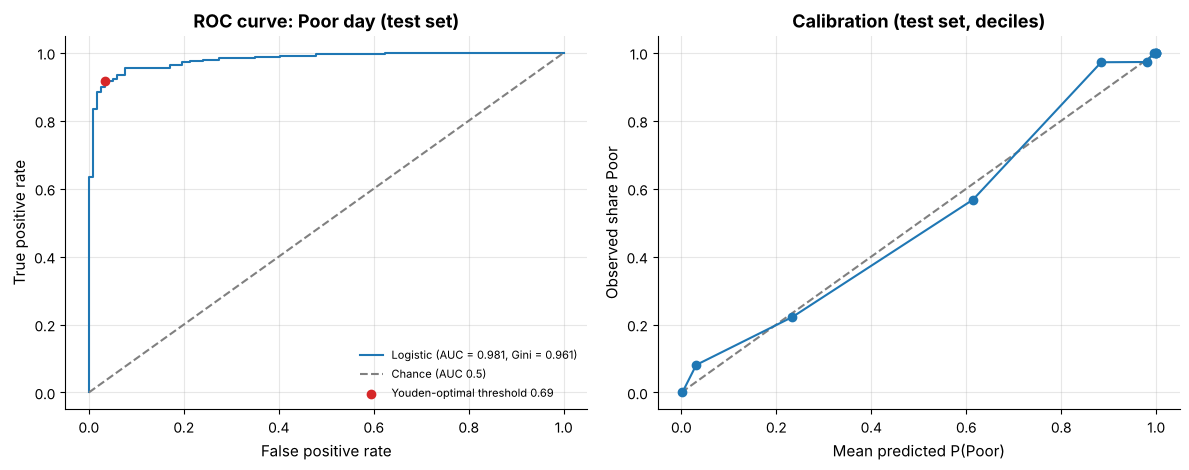

In [7]:
fpr, tpr, thr = roc_curve(y_te, p_te)
j = np.argmax(tpr - fpr)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ax[0].plot(fpr, tpr, label=f"Logistic (AUC = {m_log['ROC_AUC']:.3f}, Gini = {m_log['Gini']:.3f})")
ax[0].plot([0, 1], [0, 1], "--", color="grey", label="Chance (AUC 0.5)")
ax[0].scatter(fpr[j], tpr[j], color="C3", zorder=3, label=f"Youden-optimal threshold {thr[j]:.2f}")
ax[0].set(title="ROC curve: Poor day (test set)", xlabel="False positive rate", ylabel="True positive rate")
ax[0].legend(fontsize=8, loc="lower right")
cal = hl_te[3]
ax[1].plot([0, 1], [0, 1], "--", color="grey")
ax[1].plot(cal["mean_p"], cal["observed_poor"] / cal["n"], "o-")
ax[1].set(title="Calibration (test set, deciles)", xlabel="Mean predicted P(Poor)", ylabel="Observed share Poor")
plt.tight_layout(); save_figure(fig, "04_roc_calibration"); plt.show()

### Choosing the threshold
0.5 is a convention, not a law. For a health warning, *missing* a Poor day (false negative) is worse than a false
alarm. With a cost ratio of 3 : 1 (FN : FP), the threshold that minimises expected cost is chosen on the **training**
data and then evaluated on the test set.

In [8]:
p_tr = logit.predict(sm.add_constant(X_tr))
grid_t = np.round(np.arange(.05, .96, .01), 2)
cost = [3 * ((p_tr < t) & (y_tr == 1)).sum() + ((p_tr >= t) & (y_tr == 0)).sum() for t in grid_t]
t_star = float(grid_t[int(np.argmin(cost))])
rows = []
for t in (0.5, t_star):
    pr = (p_te >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pr).ravel()
    rows.append({"threshold": t, "missed Poor days (FN)": fn, "false alarms (FP)": fp,
                 **{k: v for k, v in classification_metrics(y_te, pr, p_te).items() if k != "ROC_AUC"}})
thr_tab = pd.DataFrame(rows)
thr_tab.round(3)

,threshold,missed Poor days (FN),false alarms (FP),Accuracy,Precision,Recall,F1
0,0.50,11,11,0.940,0.956,0.956,0.956
1,0.35,7,23,0.918,0.913,0.972,0.942


**Logistic regression: findings** (stratified 80/20 split; 68% of days are Poor)

* **Overall fit:** the likelihood-ratio test against an intercept-only model is overwhelming (p < 0.001) and
  McFadden's pseudo R² is 0.741 (values above 0.4 are usually considered excellent).
* **Wald tests:** significant at 5% are PM2.5, PM10, NOx, CO, O3 and NO2. NO, NH3, SO2 and all three season dummies
  are not significant once pollutants are known.
* **Odds ratios:** each extra 1 µg/m³ of PM2.5 multiplies the odds of a Poor day by 1.054 (so +10 µg/m³ multiplies
  them by 1.69); each extra 1 mg/m³ of CO multiplies them by 1.81. NO2's odds ratio is slightly below 1, another
  artefact of correlated predictors rather than a protective effect.
* **Probability estimation:** a median monsoon day has η = -3.65 and P(Poor) = 0.025; adding 10 µg/m³ of PM2.5
  raises it to 0.042.
* **Quasi-separation:** statsmodels warns that about 27% of training days are predicted almost perfectly, which is
  expected because Poor is defined from AQI, which is computed from these pollutants. The model converged and all
  standard errors are finite, but coefficients may be inflated and Wald p-values are treated as approximate; the
  model is judged mainly on held-out performance.
* **Classification table (threshold 0.5):** 238 Poor and 106 not-Poor days correct; 11 missed Poor days and 11 false
  alarms. Accuracy 0.940 against a no-information rate of 0.680; precision = recall = 0.956.
* **ROC and Gini:** AUC = 0.981, Gini = 2 × AUC - 1 = 0.961.
* **Hosmer-Lemeshow:** chi² = 5.24, df = 8, p = 0.73 on training data and p = 0.60 on test data: no evidence of
  poor fit. The calibration plot lies close to the diagonal. (Several deciles have expected counts below 1, so the
  test is approximate.)
* **Threshold:** with missed Poor days costing 3 times a false alarm, the training-optimal threshold is 0.35. On the
  test set it cuts missed Poor days from 11 to 7 at the cost of 12 extra false alarms (recall 0.972 vs 0.956), the
  right trade for a public-health warning.

## Part B: Multinomial logistic regression for the 3 AQI groups
With K = 3 classes the model fits K - 1 = 2 logit equations against a baseline class (Low):
log(P(Moderate)/P(Low)) and log(P(High)/P(Low)).

In [9]:
ct = pd.crosstab(df["Season"], df["AQI_Group"]).reindex(index=SEASONS, columns=GROUPS)
ct

AQI_Group,Low,Moderate,High
Season,,,
Winter,0,21,430
Summer,1,94,365
Monsoon,159,284,167
Post-monsoon,2,24,279


**Why season is left out of the multinomial model.** Winter has **no** Low days and summer and post-monsoon only one
or two. A season dummy would then perfectly predict "not Low" (quasi-complete separation): the maximum-likelihood
coefficient goes to minus infinity and its standard error explodes. The multinomial model therefore uses the nine
pollutants only, standardised (mean 0, SD 1) so that coefficients are comparable across pollutants.

In [10]:
code_map = {"Low": 0, "Moderate": 1, "High": 2}
y3 = df["AQI_Group"].map(code_map)
X_tr3, X_te3, y_tr3, y_te3 = train_test_split(X, y3, test_size=TEST_SIZE, random_state=SEED, stratify=y3)
Xp_tr, Xp_te = X_tr3[POLLUTANTS], X_te3[POLLUTANTS]
sc = StandardScaler().fit(Xp_tr)

def scale_p(Xd):
    Z = pd.DataFrame(sc.transform(Xd), index=Xd.index, columns=Xd.columns)
    return sm.add_constant(Z)

mnl = sm.MNLogit(y_tr3, scale_p(Xp_tr)).fit(method="newton", maxiter=200, disp=0)
print("converged:", mnl.mle_retvals["converged"])
print(mnl.summary())

converged: True
                          MNLogit Regression Results                          
Dep. Variable:              AQI_Group   No. Observations:                 1460
Model:                        MNLogit   Df Residuals:                     1440
Method:                           MLE   Df Model:                           18
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.7170
Time:                        10:38:53   Log-Likelihood:                -337.42
converged:                       True   LL-Null:                       -1192.3
Covariance Type:            nonrobust   LLR p-value:                     0.000
AQI_Group=1       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          15.8530      2.011      7.885      0.000      11.912      19.794
PM2.5          10.2187      1.816      5.626      0.000       6.659      13.779
PM10            0.2387      0.66

In [11]:
rrr = np.exp(mnl.params).rename(columns={0: "Moderate vs Low", 1: "High vs Low"})
pv = mnl.pvalues.rename(columns={0: "p (Moderate)", 1: "p (High)"})
mnl_tab = pd.concat([rrr, pv], axis=1).drop("const")
mnl_tab.columns = ["RRR Moderate vs Low", "RRR High vs Low", "p Moderate", "p High"]
mnl_tab.round(3)

,RRR Moderate vs Low,RRR High vs Low,p Moderate,p High
PM2.5,27410.791,5113321.338,0.000,0.000
PM10,1.270,24.262,0.720,0.000
NO,0.555,0.317,0.370,0.123
NO2,0.629,0.270,0.450,0.059
NOx,12.859,36.117,0.005,0.000
NH3,1.776,2.690,0.174,0.045
CO,9.112,34.769,0.279,0.084
SO2,1.009,1.251,0.991,0.781
O3,15.264,34.949,0.000,0.000


The relative risk ratio (RRR = e^β) is the multiplicative change in P(group)/P(Low) for a one-standard-deviation
increase in the pollutant.

In [12]:
proba3 = np.asarray(mnl.predict(scale_p(Xp_te)))
pred3 = proba3.argmax(axis=1)
print(pd.DataFrame(confusion_matrix(y_te3, pred3), index=["Actual Low", "Actual Moderate", "Actual High"],
                   columns=["Pred Low", "Pred Moderate", "Pred High"]))
m3 = classification_metrics(y_te3, pred3, proba3)
print({k: round(v, 3) for k, v in m3.items()})
print(classification_report(y_te3, pred3, target_names=GROUPS, digits=3))

                 Pred Low  Pred Moderate  Pred High
Actual Low             25              7          0
Actual Moderate         3             67         15
Actual High             1             10        238
{'Accuracy': 0.902, 'Precision': 0.867, 'Recall': 0.842, 'F1': 0.854, 'ROC_AUC': 0.973}
              precision    recall  f1-score   support

         Low      0.862     0.781     0.820        32
    Moderate      0.798     0.788     0.793        85
        High      0.941     0.956     0.948       249

    accuracy                          0.902       366
   macro avg      0.867     0.842     0.854       366
weighted avg      0.901     0.902     0.901       366



**Multinomial logistic regression: findings** (Low = baseline; coefficients per 1 SD of each pollutant)

* Converged; McFadden pseudo R² = 0.717.
* **PM2.5 dominates both equations** (z = 5.6 and 8.1). Its relative risk ratios are enormous (one SD of PM2.5,
  about 82 µg/m³, multiplies the odds of High vs Low by about 5 million) because the groups are almost separable on
  PM2.5; read them as "decisive", not as precise numbers.
* PM10 matters for High vs Low (RRR 24, p < 0.001) but not for Moderate vs Low (p = 0.72): coarse dust pushes days
  into the High band. NOx and O3 are significant in both equations.
* **Classification:** accuracy 0.902 against 0.680 for always predicting High; macro precision 0.867, recall 0.842,
  F1 0.854; one-vs-rest ROC-AUC 0.973. High is easiest (F1 0.948), Low the hardest (F1 0.820, only 32 test days).
* **Errors are ordinal:** almost all mistakes are between neighbouring groups. Only one High day was predicted Low
  and no Low day was predicted High.

## Part C: CART decision trees
CART grows a binary tree by choosing, at each node, the split that most reduces **Gini impurity**
(1 - Σ p_k²) for classification or the **sum of squared errors** for regression. Depth and leaf size are tuned by
5-fold cross-validation on the training data only, then the tree is **pruned** by cost-complexity (α).

In [13]:
def fit_tree(Xtr, ytr, scoring):
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    grid = {"max_depth": [2, 3, 4, 5, 6, 8], "min_samples_leaf": [5, 10, 20, 40]}
    gs = GridSearchCV(DecisionTreeClassifier(criterion="gini", random_state=SEED), grid, cv=cv, scoring=scoring)
    gs.fit(Xtr, ytr)
    return gs.best_estimator_, gs.best_params_

tree_b, bp_b = fit_tree(X_tr[POLLUTANTS], y_tr, "roc_auc")
print("Binary tree, tuned:", bp_b, "| leaves:", tree_b.get_n_leaves())

Binary tree, tuned: {'max_depth': 8, 'min_samples_leaf': 20} | leaves: 23


leaves: unpruned 23 -> pruned 20


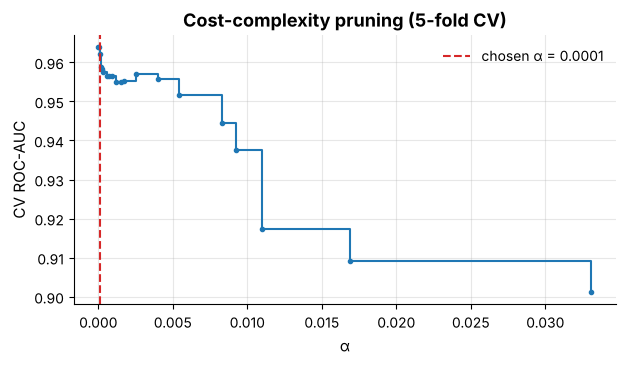

In [14]:
path = tree_b.cost_complexity_pruning_path(X_tr[POLLUTANTS], y_tr)
alphas = np.unique(path.ccp_alphas)[:-1]
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
scores = [cross_val_score(DecisionTreeClassifier(random_state=SEED, ccp_alpha=a,
                                                 max_depth=bp_b["max_depth"], min_samples_leaf=bp_b["min_samples_leaf"]),
                          X_tr[POLLUTANTS], y_tr, cv=cv5, scoring="roc_auc").mean() for a in alphas]
scores = np.array(scores)
best_i = int(np.argmax(scores))
# one-standard-error style rule: the simplest tree within 0.005 AUC of the best
ok = np.where(scores >= scores[best_i] - 0.005)[0]
alpha_star = float(alphas[ok.max()])
tree_p = DecisionTreeClassifier(random_state=SEED, ccp_alpha=alpha_star, max_depth=bp_b["max_depth"],
                                min_samples_leaf=bp_b["min_samples_leaf"]).fit(X_tr[POLLUTANTS], y_tr)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(alphas, scores, marker=".", drawstyle="steps-post")
ax.axvline(alpha_star, color="C3", ls="--", label=f"chosen α = {alpha_star:.4f}")
ax.set(title="Cost-complexity pruning (5-fold CV)", xlabel="α", ylabel="CV ROC-AUC"); ax.legend()
save_figure(fig, "04_pruning_path"); plt.show()
print(f"leaves: unpruned {tree_b.get_n_leaves()} -> pruned {tree_p.get_n_leaves()}")

In [15]:
p_tb = tree_p.predict_proba(X_te[POLLUTANTS])[:, 1]
mb = classification_metrics(y_te, tree_p.predict(X_te[POLLUTANTS]), p_tb)
mb["Gini"] = 2 * mb["ROC_AUC"] - 1
p_tb_un = tree_b.predict_proba(X_te[POLLUTANTS])[:, 1]
mb_un = classification_metrics(y_te, tree_b.predict(X_te[POLLUTANTS]), p_tb_un)
mb_un["Gini"] = 2 * mb_un["ROC_AUC"] - 1
pd.DataFrame([{"Tree": "tuned, unpruned", "leaves": tree_b.get_n_leaves(), **mb_un},
              {"Tree": "pruned", "leaves": tree_p.get_n_leaves(), **mb}]).round(3)

,Tree,leaves,Accuracy,Precision,Recall,F1,ROC_AUC,Gini
0,"tuned, unpruned",23,0.902,0.914,0.944,0.929,0.966,0.932
1,pruned,20,0.902,0.914,0.944,0.929,0.960,0.920


Gini feature importance:
 PM2.5    0.758
PM10     0.098
O3       0.066
CO       0.052
NO2      0.016
NO       0.007
NOx      0.003
NH3      0.000
SO2      0.000

|--- PM2.5 <= 76.32
|   |--- PM10 <= 190.15
|   |   |--- CO <= 4.25
|   |   |   |--- O3 <= 54.77
|   |   |   |   |--- PM2.5 <= 72.15
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- PM2.5 >  72.15
|   |   |   |   |   |--- class: 0
|   |   |   |--- O3 >  54.77
|   |   |   |   |--- NO2 <= 45.65
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |--- NO2 >  45.65
|   |   |   |   |   |--- class: 1
|   |   |--- CO >  4.25
|   |   |   |--- class: 1
|   |--- PM10 >  190.15
|   |   |--- O3 <= 50.26
|   |   |   |--- class: 1
|   |   |--- O3 >  50.26
|   |   |   |--- PM10 <= 232.00
|   |   |   |   |--- class: 1
|   |   |   |--- PM10 >  232.00
|   |   |   |   |--- class: 1
|--- PM2.5 >  76.32
|   |--- PM2.5 <= 90.58
|   |   |--- O3 <= 46.64
|   |   |   |--- NO <= 24.77
|   |   |   |   |--- class

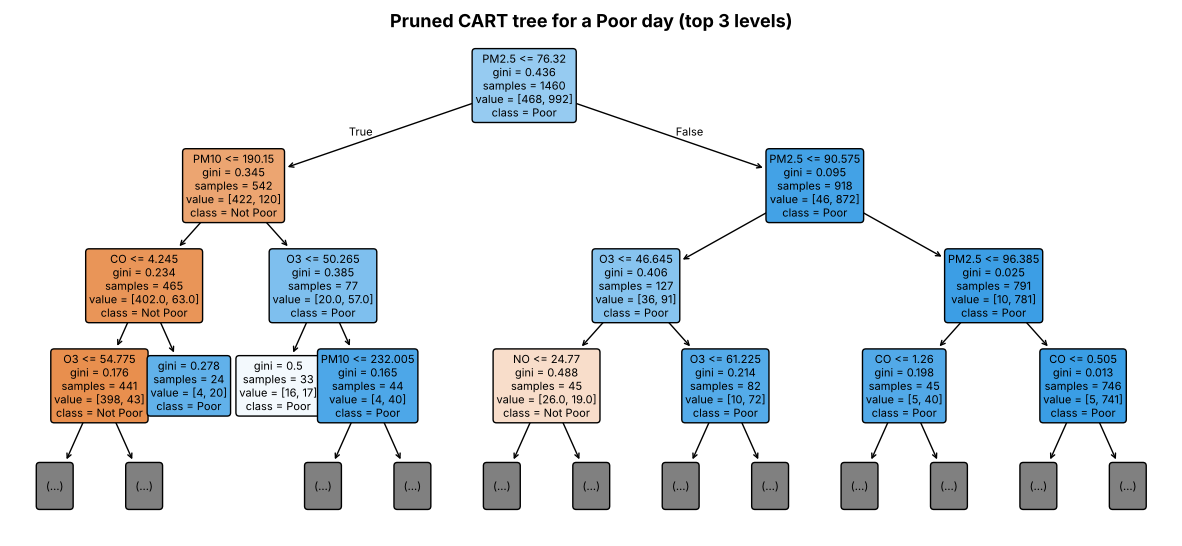

In [16]:
imp = pd.Series(tree_p.feature_importances_, index=POLLUTANTS).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(15, 6.5))
plot_tree(tree_p, feature_names=POLLUTANTS, class_names=["Not Poor", "Poor"], filled=True, fontsize=8,
          max_depth=3, ax=ax, impurity=True, proportion=False, rounded=True)
ax.set_title("Pruned CART tree for a Poor day (top 3 levels)")
save_figure(fig, "04_tree_poor"); plt.show()
print("Gini feature importance:\n", imp.round(3).to_string())
print()
print(export_text(tree_p, feature_names=POLLUTANTS, max_depth=4))

### Three-class tree and a regression tree for AQI

In [17]:
tree_3, bp_3 = fit_tree(Xp_tr, y_tr3, "f1_macro")
m_t3 = classification_metrics(y_te3, tree_3.predict(Xp_te), tree_3.predict_proba(Xp_te))
print("3-class tree:", bp_3, {k: round(v, 3) for k, v in m_t3.items()})

Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(df[POLLUTANTS], df["AQI"], test_size=TEST_SIZE, random_state=SEED)
gs_r = GridSearchCV(DecisionTreeRegressor(random_state=SEED),
                    {"max_depth": [3, 4, 5, 6, 8, 10], "min_samples_leaf": [5, 10, 20, 40]},
                    cv=KFold(5, shuffle=True, random_state=SEED), scoring="neg_root_mean_squared_error").fit(Xr_tr, yr_tr)
tree_r = gs_r.best_estimator_
m_tr = regression_metrics(yr_te, tree_r.predict(Xr_te), n_features=len(POLLUTANTS))
print("Regression tree:", gs_r.best_params_, "| leaves:", tree_r.get_n_leaves(),
      {k: round(v, 3) for k, v in m_tr.items()})
imp_r = pd.Series(tree_r.feature_importances_, index=POLLUTANTS).sort_values(ascending=False)
print("importance:", imp_r.round(3).head(4).to_dict())

3-class tree: {'max_depth': 5, 'min_samples_leaf': 20} {'Accuracy': 0.872, 'Precision': 0.808, 'Recall': 0.804, 'F1': 0.805, 'ROC_AUC': 0.942}
Regression tree: {'max_depth': 10, 'min_samples_leaf': 10} | leaves: 112 {'R2': 0.886, 'Adj_R2': 0.884, 'RMSE': 40.283, 'MAE': 28.589}
importance: {'PM2.5': 0.852, 'PM10': 0.069, 'O3': 0.034, 'CO': 0.025}


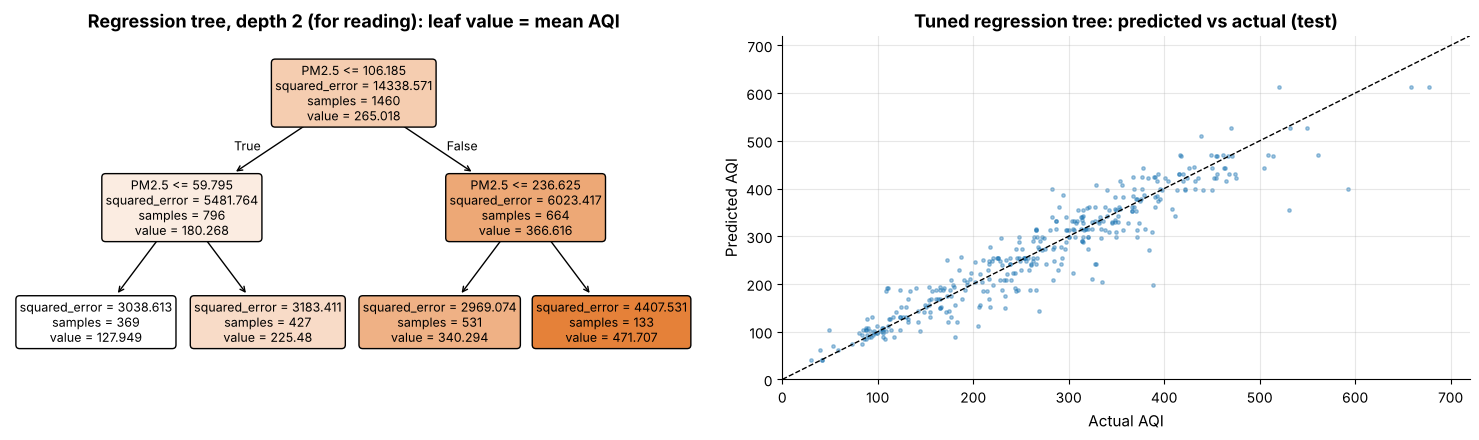

In [18]:
small = DecisionTreeRegressor(max_depth=2, random_state=SEED).fit(Xr_tr, yr_tr)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
plot_tree(small, feature_names=POLLUTANTS, filled=True, fontsize=9, ax=ax[0], rounded=True)
ax[0].set_title("Regression tree, depth 2 (for reading): leaf value = mean AQI")
ax[1].scatter(yr_te, tree_r.predict(Xr_te), s=6, alpha=.4)
lim = [0, 720]; ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set(xlim=lim, ylim=lim, title="Tuned regression tree: predicted vs actual (test)", xlabel="Actual AQI",
          ylabel="Predicted AQI")
plt.tight_layout(); save_figure(fig, "04_regression_tree"); plt.show()

In [19]:
reg_comp = pd.read_csv(TABLES_DIR / "regression_comparison.csv")
reg_comp = reg_comp[reg_comp["Model"] != "CART regression tree"]
reg_comp = pd.concat([reg_comp, pd.DataFrame([{"Model": "CART regression tree", "k": len(POLLUTANTS), **m_tr}])],
                     ignore_index=True)
save_table(reg_comp.round(3), "regression_comparison")
reg_comp[["Model", "R2", "RMSE", "MAE"]].round(3)

,Model,R2,RMSE,MAE
0,Simple linear (PM2.5),0.775,56.741,42.298
1,Multiple linear (AIC-selected),0.881,41.260,31.385
2,Polynomial (PM2.5 squared),0.885,40.475,30.731
3,CART regression tree,0.886,40.283,28.589


### The CHAID idea: a chi-square test of season against AQI group
CHAID (Chi-squared Automatic Interaction Detection) chooses each split by the most significant chi-square test of
independence between a categorical predictor and the target, and can make multi-way splits. scikit-learn has no
CHAID, so its splitting criterion is shown directly.

In [20]:
chi2, p_chi, dof, expected = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(ct)
print(f"chi2 = {chi2:.1f}, df = {dof}, p = {p_chi:.3g}, Cramér's V = {cramers_v:.2f}")
print("smallest expected count:", round(float(expected.min()), 1), "(all >= 5, so the test is valid)")
std_res = (ct - expected) / np.sqrt(expected)
std_res.round(1)

AQI_Group     Low  Moderate  High
Season                           
Winter          0        21   430
Summer          1        94   365
Monsoon       159       284   167
Post-monsoon    2        24   279
chi2 = 779.6, df = 6, p = 4e-165, Cramér's V = 0.46
smallest expected count: 27.1 (all >= 5, so the test is valid)


AQI_Group,Low,Moderate,High
Season,,,
Winter,-6.3,-8.2,7.1
Summer,-6.2,-1.2,3.0
Monsoon,14.3,12.0,-12.2
Post-monsoon,-4.8,-5.6,5.0


**Decision trees: findings**

* **Tuning and pruning:** cross-validation picked depth 8 with at least 20 days per leaf (23 leaves). Cost-complexity
  pruning with a "simplest tree within 0.005 AUC of the best" rule removes 3 leaves (20 left) with identical
  accuracy, F1 and recall; test AUC changes only from 0.966 to 0.960.
* **How the tree reads:** the root split is **PM2.5 ≤ 76.3 µg/m³**. Above it almost every day is Poor. Below it,
  PM10 above 190 µg/m³ or CO above about 4.3 mg/m³ still pushes a day to Poor. Interestingly, 76 µg/m³ is close to
  the official PM2.5 breakpoint of 90 µg/m³ at which the PM2.5 sub-index itself crosses 200: the tree has partly
  rediscovered the AQI formula, which it must, since AQI is computed from these readings.
* **Gini importance:** PM2.5 0.76, PM10 0.10, O3 0.07, CO 0.05, the rest ≈ 0. Note that CART's Gini *impurity*
  (1 - Σp²) is different from the Gini *coefficient* of the ROC curve (2·AUC - 1).
* **Three-class tree:** accuracy 0.872, macro F1 0.805, below the multinomial model (0.902 / 0.854).
* **Regression tree (CART for AQI):** depth 10, 112 leaves, test R² = 0.886, RMSE 40.3, MAE 28.6, essentially tied
  with the polynomial regression (RMSE 40.5) and with the lowest MAE of all. PM2.5 provides 85% of the importance.
  It gives a step-function prediction, and the depth-2 tree shows the logic: PM2.5 sets the first two splits.
* **CHAID idea:** season and AQI group are strongly associated (chi² = 779.6, df = 6, p ≈ 4e-165, Cramér's V =
  0.46). Standardised residuals show where: Monsoon has 14.3 SD more Low days than independence predicts and Winter
  7.1 SD more High days. A CHAID tree would therefore make **season** its first, multi-way split.

## Part D: Model comparison

In [21]:
rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=3, random_state=SEED, n_jobs=-1).fit(X_tr[POLLUTANTS], y_tr)
p_rf = rf.predict_proba(X_te[POLLUTANTS])[:, 1]
m_rf = classification_metrics(y_te, (p_rf >= .5).astype(int), p_rf); m_rf["Gini"] = 2 * m_rf["ROC_AUC"] - 1

rows = [
    {"Task": "Poor day (binary)", "Model": "Logistic regression", **m_log},
    {"Task": "Poor day (binary)", "Model": "CART tree (pruned)", **mb},
    {"Task": "Poor day (binary)", "Model": "Random forest (benchmark, beyond syllabus)", **m_rf},
    {"Task": "AQI group (3 classes, macro)", "Model": "Multinomial logistic", **m3, "Gini": np.nan},
    {"Task": "AQI group (3 classes, macro)", "Model": "CART tree", **m_t3, "Gini": np.nan},
]
clf_comp = pd.DataFrame(rows)

# 5-fold cross-validated AUC on all data (binary task) for stability
cvs = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv_auc = {
    "Logistic regression": cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(C=1e6, max_iter=5000)), X, y, cv=cvs, scoring="roc_auc"),
    "CART tree (pruned)": cross_val_score(DecisionTreeClassifier(random_state=SEED, ccp_alpha=alpha_star, max_depth=bp_b["max_depth"], min_samples_leaf=bp_b["min_samples_leaf"]), X[POLLUTANTS], y, cv=cvs, scoring="roc_auc"),
    "Random forest (benchmark, beyond syllabus)": cross_val_score(RandomForestClassifier(n_estimators=400, min_samples_leaf=3, random_state=SEED, n_jobs=-1), X[POLLUTANTS], y, cv=cvs, scoring="roc_auc"),
}
clf_comp["CV5 AUC"] = clf_comp["Model"].map(lambda m: cv_auc[m].mean() if m in cv_auc else np.nan)
clf_comp["CV5 AUC sd"] = clf_comp["Model"].map(lambda m: cv_auc[m].std(ddof=1) if m in cv_auc else np.nan)

# forward-in-time check: train 2015-2018, test 2019
tr_t, te_t = (df["Year"] <= 2018).values, (df["Year"] == 2019).values
lt = sm.Logit(y[tr_t], sm.add_constant(X[tr_t])).fit(disp=0)
pt = lt.predict(sm.add_constant(X[te_t]))
tt = DecisionTreeClassifier(random_state=SEED, ccp_alpha=alpha_star, max_depth=bp_b["max_depth"],
                            min_samples_leaf=bp_b["min_samples_leaf"]).fit(X.loc[tr_t, POLLUTANTS], y[tr_t])
rft = RandomForestClassifier(n_estimators=400, min_samples_leaf=3, random_state=SEED, n_jobs=-1).fit(X.loc[tr_t, POLLUTANTS], y[tr_t])
t2019 = {"Logistic regression": roc_auc_score(y[te_t], pt),
         "CART tree (pruned)": roc_auc_score(y[te_t], tt.predict_proba(X.loc[te_t, POLLUTANTS])[:, 1]),
         "Random forest (benchmark, beyond syllabus)": roc_auc_score(y[te_t], rft.predict_proba(X.loc[te_t, POLLUTANTS])[:, 1])}
clf_comp["2019 AUC"] = clf_comp["Model"].map(t2019)
save_table(clf_comp.round(3), "classifier_comparison")
clf_comp.round(3)

,Task,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Gini,CV5 AUC,CV5 AUC sd,2019 AUC
0,Poor day (binary),Logistic regression,0.940,0.956,0.956,0.956,0.981,0.961,0.980,0.004,0.976
1,Poor day (binary),CART tree (pruned),0.902,0.914,0.944,0.929,0.960,0.920,0.957,0.007,0.954
2,Poor day (binary),"Random forest (benchmark, beyond syllabus)",0.932,0.938,0.964,0.950,0.982,0.965,0.980,0.002,0.971
3,"AQI group (3 classes, macro)",Multinomial logistic,0.902,0.867,0.842,0.854,0.973,NaN,NaN,NaN,NaN
4,"AQI group (3 classes, macro)",CART tree,0.872,0.808,0.804,0.805,0.942,NaN,NaN,NaN,NaN


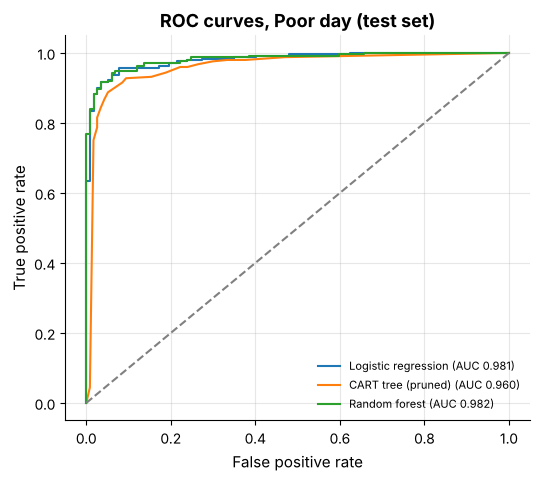

In [22]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, pr in [("Logistic regression", p_te), ("CART tree (pruned)", p_tb), ("Random forest", p_rf)]:
    f_, t_, _ = roc_curve(y_te, pr)
    ax.plot(f_, t_, label=f"{name} (AUC {roc_auc_score(y_te, pr):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set(title="ROC curves, Poor day (test set)", xlabel="False positive rate", ylabel="True positive rate")
ax.legend(fontsize=8, loc="lower right")
save_figure(fig, "04_roc_comparison"); plt.show()

**Which classifier wins?**

* **Poor-day task: logistic regression.** It has the best accuracy (0.940) and F1 (0.956), the joint-best AUC (0.981,
  cross-validated 0.980 ± 0.004) and the best forward-in-time AUC (0.976 when trained on 2015-18 and tested on 2019).
  It is also the most interpretable through odds ratios and the best calibrated (Hosmer-Lemeshow p = 0.60).
* The pruned CART tree is clearly weaker (AUC 0.960) but gives readable if-then rules; its value is explanation, not
  accuracy.
* The random forest, included only as a beyond-syllabus benchmark, does **not** beat logistic regression (AUC 0.982
  vs 0.981 on the split, 0.971 vs 0.976 on 2019). When the outcome is a smooth threshold of a few strong
  predictors, a well-specified logistic model is as good as a black box.
* **Three-group task: multinomial logistic regression** beats the CART tree on every measure (accuracy 0.902 vs
  0.872, macro F1 0.854 vs 0.805, AUC 0.973 vs 0.942).
* Compare models only within a task: the 3-class rows are macro-averaged and use one-vs-rest AUC.

## A note on unstructured data
Everything above uses **structured** data: numeric columns in a table. Much air-quality information is
**unstructured**: news reports of stubble burning, social-media complaints, satellite images of fire counts, and
free-text CPCB bulletins. Such data must first be turned into features before a tree or regression can use it, for
example: (1) *text*: counting mentions of "stubble", "Diwali" or "firecrackers" per day, or a sentiment score, via
tokenisation and TF-IDF; (2) *images*: NASA FIRMS fire counts over Punjab and Haryana extracted from satellite
imagery; (3) *events*: a festival calendar coded as dummy variables. A decision tree is well suited to such mixed,
engineered features because it needs no scaling and handles thresholds naturally. Adding a "fire count in Punjab
yesterday" feature is the most promising extension of this project for predicting the October-November peak.

## Export the classifiers for the app

In [23]:
t = tree_p.tree_
clf_export = {
    "logit": {"columns": list(logit.params.index), "params": {k: float(v) for k, v in logit.params.items()},
              "threshold_cost3": t_star},
    "multinomial": {"classes": GROUPS, "pollutants": POLLUTANTS, "columns": list(mnl.params.index),
                    "params": mnl.params.values.tolist(), "scaler_mean": sc.mean_.tolist(),
                    "scaler_scale": sc.scale_.tolist()},
    "tree_poor": {"feature_names": POLLUTANTS, "children_left": t.children_left.tolist(),
                  "children_right": t.children_right.tolist(), "feature": t.feature.tolist(),
                  "threshold": t.threshold.tolist(), "value": t.value[:, 0, :].tolist()},
    "source": "cleaned dataset (notebook 01)",
    "n_train": int(len(X_tr)),
}
print("saved:", save_json(clf_export, "classifier_models").name)

saved: classifier_models.json


In [24]:
from src import predict_utils as pu
clf_loaded = pu.load_classifiers()
chk = X_te.head(200)
rows_ = [chk.loc[i, POLLUTANTS].to_dict() for i in chk.index]
seas = df.loc[chk.index, "Season"]
d_logit = np.abs(np.array([pu.predict_poor_prob(r, s, clf_loaded) for r, s in zip(rows_, seas)])
                 - logit.predict(sm.add_constant(chk)).values).max()
d_tree = np.mean(np.array([pu.predict_tree_poor(r, clf_loaded)[0] for r in rows_]) != tree_p.predict(chk[POLLUTANTS]))
chk3 = X_te3.head(200)
rows3 = [chk3.loc[i, POLLUTANTS].to_dict() for i in chk3.index]
d_mnl = np.abs(np.array([[pu.predict_group(r, clf_loaded)[k] for k in GROUPS] for r in rows3])
               - np.asarray(mnl.predict(scale_p(chk3[POLLUTANTS])))).max()
print(f"logistic max probability difference: {d_logit:.2e}")
print(f"tree: share of days predicted differently: {d_tree:.3f}")
print(f"multinomial max probability difference: {d_mnl:.2e}")
assert d_logit < 1e-6 and d_tree == 0 and d_mnl < 1e-6, "export does not match the fitted models"

logistic max probability difference: 4.44e-16
tree: share of days predicted differently: 0.000
multinomial max probability difference: 1.33e-15
